# Fb -> Adipocyte trajectory: PAGA (revision)

Re-run of the PAGA trajectory analysis in
`notebooks_github/03_Scell2Xenium_Fb_Adipocyte_plotting2.ipynb` on the current joint object and
the harmonised annotation.

| | original (2025-07) | this notebook |
|---|---|---|
| object | `adata_scell2xenium_Fibro_2025-07-09.zarr` (scRNA-seq + Xenium) | `thyAgeing_Fb_scell_multiome_xenium_scvi_filt_2026-08-27.zarr` (146,178 cells x 4,807 genes, **+ multiome**) |
| labels | `Fb_int_anno`, built in-notebook from a leiden re-clustering | **`taa_l3_cmx`** from `thyAgeing_Fb_scell_multiome_xenium_anno_cmx_2026-08-29.csv` |
| figures | scanpy defaults | Nature spec via `plotting.fb_pub_figs` -- 89/130/183 mm widths, 5-7 pt Arial, Type-42 fonts, 600 dpi rasterised point clouds |

**What is here and what is not.** Only the PAGA trajectory, the ForceAtlas2 embedding it
initialises, and the marker dotplots. The original notebook spent most of its length *defining*
the adipose populations by re-clustering; that job now belongs to `Fbs_smx_harmonize.ipynb`, whose
output CSV is read here as given.

**Runtime.** Everything except §5 takes about a minute. `sc.tl.draw_graph` is the expensive step --
a force layout over 146k cells and 2.7M edges.

---

## 0. Header

Cells below are carried over verbatim from the original notebook so the two run in the same
environment with the same defaults. The Nature-format layer is applied *after* them in §1, so its
`savefig.dpi` / `pdf.fonttype` / style settings win over the `sc.settings.set_figure_params` calls
here.

In [1]:
import sys 
import os
from datetime import datetime
import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import scvi
import hdf5plugin
import matplotlib.pyplot as plt
import seaborn as sns

# Add repo path to sys path (allows to access scripts and metadata from repo)
# repo_path = os.path.split(os.getcwd())[0]
repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')


/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [2]:
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")

In [3]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [4]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
plt.style.use(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

In [5]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data'

In [6]:
sys.path.append('/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')

In [7]:
from utils import get_latest_version,update_obs,freq_by_donor
from anno_levels import get_ct_levels, get_ct_palette, age_group_levels, age_group_palette

In [8]:
sc.settings.set_figure_params(dpi = 80, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

## 1. Nature format and the shared vocabulary

`plotting.fb_pub_figs` is the same module that draws the Fb ageing publication figures, so a
population is one colour and one name here and there. Applying `P.set_style()` last makes the
Nature settings authoritative: 5-7 pt Arial from `thyAgeing.mplstyle`, Type-42 embedded fonts
(live text in Illustrator), 600 dpi for the rasterised scatter layer, and `savefig.bbox='standard'`
so a figure asked for at 89 mm is 89 mm on the page.

**Population order.** `Fb-TGFB+` is placed **after `Fb-interm`**, per VK. The order set here drives
the dotplot rows, the PAGA node order and the categorical dtype -- change `POP_ORDER` in this cell
and everything downstream follows.

In [9]:
%matplotlib inline
sys.path.insert(2, '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts')
import plotting.fb_pub_figs as P

P.set_style()

# Fb-TGFB+ after Fb-interm (VK, 2026-09-02). This is P.POP_ORDER already; restated here so the
# order is visible and editable in the notebook rather than buried in the module.
POP_ORDER = ['Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-interm', 'Fb-TGFB+', 'Fb-adipo', 'Adipocyte']
P.POP_ORDER = POP_ORDER

FIGS = f'{plot_path}/Fb_adipo_paga_revision'
RES  = f'{repo_path}/results/Fb_adipo_paga_revision'
os.makedirs(FIGS, exist_ok=True); os.makedirs(RES, exist_ok=True)

print(f'font   : {plt.rcParams["font.sans-serif"][0]} | base {plt.rcParams["font.size"]} pt '
      f'| ticks {plt.rcParams["xtick.labelsize"]} pt | pdf fonttype {plt.rcParams["pdf.fonttype"]}')
print(f'output : {FIGS}\n         {RES}')

font   : Arial | base 7.0 pt | ticks 5.0 pt | pdf fonttype 42
output : /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision
         /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/results/Fb_adipo_paga_revision


In [10]:
# The population and modality colours, for reference. Fb-adipo and Adipocyte are two tints of
# yellow because they are two points on ONE adipose axis, not two unrelated states.
pd.DataFrame({'level': POP_ORDER + P.MODALITY_ORDER,
              'kind': ['population'] * len(POP_ORDER) + ['modality'] * len(P.MODALITY_ORDER),
              'name': POP_ORDER + [P.MODALITY_NAMES[m] for m in P.MODALITY_ORDER],
              'colour': [P.POP_COLORS[p] for p in POP_ORDER]
                        + [P.MODALITY_COLORS[m] for m in P.MODALITY_ORDER]})

,level,kind,name,colour
0,Fb-interlo,population,Fb-interlo,#FE6100
1,Fb-perilo,population,Fb-perilo,#648FFF
2,Fb-med,population,Fb-med,#DC267F
3,Fb-interm,population,Fb-interm,#18868F
4,Fb-TGFB+,population,Fb-TGFB+,#785EF0
5,Fb-adipo,population,Fb-adipo,#ffd473
6,Adipocyte,population,Adipocyte,#FFB000
7,scell,modality,scRNA-seq,#82CD29
8,multiome,modality,Multiome (snRNA),#252525
9,xenium,modality,Xenium,#8B0000


## 2. Object and annotation

The labels live in a CSV next to the object rather than inside it, so nothing here depends on
re-writing a 300 MB file. The CSV is authoritative for `donor` / `age` / `age_months` /
`age_group` / `sex` as well as for the label -- the object's own copies of those columns predate
the demultiplexing fixes.

`X` is log-normalised, which is what the dotplots want; `layers['counts']` holds the raw counts and
is dropped here because nothing below uses it. The kNN graph in `obsp` is the one computed on
`X_scVI` for the UMAP, and is what PAGA reads.

`modality` is taken from `obs['batch']`. Note that this object *also* has an `obs['modality']`,
but it is spelled `cells` / `nuclei` / `xenium`; `batch` uses `scell` / `multiome` / `xenium`,
which is the vocabulary the rest of the Fb figures use.

In [11]:
OBJ      = '/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data/objects'
CMX_H5   = f'{OBJ}/thyAgeing_Fb_scell_multiome_xenium_scvi_filt_2026-08-27.zarr'
CMX_ANNO = f'{OBJ}/thyAgeing_Fb_scell_multiome_xenium_anno_cmx_2026-08-29.csv'

LABEL     = 'taa_l3_cmx'
LABEL_MOD = 'taa_l3_cmx_modality'

adata = ad.read_h5ad(CMX_H5)
del adata.layers['counts']          # raw counts unused here; X is already log-normalised
adata

AnnData object with n_obs × n_vars = 146178 × 4807
    obs: 'donor', 'chemistry_simple', 'age_group', 'modality', 'donor_comb', 'ct_ref', 'qc_n_counts', 'qc_n_genes', 'batch', 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'anno_status', 'qc_status', 'taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5', 'sample_barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap

In [12]:
anno = pd.read_csv(CMX_ANNO, index_col=0, low_memory=False)
assert adata.obs_names.is_unique and anno.index.is_unique, 'non-unique cell labels'
assert len(adata.obs_names.difference(anno.index)) == 0, 'cells missing from the annotation CSV'

print('obs["batch"] x obs["modality"] as stored in the object:')
print(pd.crosstab(adata.obs['batch'].astype(str), adata.obs['modality'].astype(str)).to_string())

for col in ['donor', 'age', 'age_months', 'age_group', 'sex', LABEL]:
    adata.obs[col] = anno.loc[adata.obs_names, col].values      # the CSV is authoritative
adata.obs['modality'] = adata.obs['batch'].astype(str)
adata.obs[LABEL] = pd.Categorical(adata.obs[LABEL].astype(str),
                                  categories=P.order_present(adata.obs[LABEL], POP_ORDER))
assert adata.obs[LABEL].isna().sum() == 0, 'unlabelled cells -- PAGA needs a complete grouping'

ORDER_CMX = list(adata.obs[LABEL].cat.categories)
adata.uns[f'{LABEL}_colors'] = [P.POP_COLORS[g] for g in ORDER_CMX]
print(f'\n{LABEL} rows, in order: {ORDER_CMX}')
print(f'kNN graph: {adata.obsp["connectivities"].nnz:,} edges, '
      f'{adata.obsp["connectivities"].nnz / adata.n_obs:.1f} per cell | '
      f'params {adata.uns["neighbors"]["params"]}')

obs["batch"] x obs["modality"] as stored in the object:
modality  cells  nuclei  xenium
batch                          
multiome      0   14535       0
scell     67535       0       0
xenium        0       0   64108



taa_l3_cmx rows, in order: ['Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-interm', 'Fb-TGFB+', 'Fb-adipo', 'Adipocyte']
kNN graph: 2,716,298 edges, 18.6 per cell | params {'method': 'umap', 'metric': 'euclidean', 'n_neighbors': np.int64(15), 'random_state': np.int64(0), 'use_rep': 'X_scVI'}


In [13]:
ct = pd.crosstab(adata.obs['modality'], adata.obs[LABEL])
ct = ct.reindex(index=P.order_present(adata.obs['modality'], P.MODALITY_ORDER), columns=ORDER_CMX)
ct.loc['TOTAL'] = ct.sum()
ct.to_csv(f'{RES}/cell_counts_{LABEL}_by_modality_{today}.csv')
ct

taa_l3_cmx,Fb-interlo,Fb-perilo,Fb-med,Fb-interm,Fb-TGFB+,Fb-adipo,Adipocyte
modality,,,,,,,
scell,17195,22629,7178,13998,1258,4847,430
multiome,4631,5134,1044,2834,271,520,101
xenium,9835,30115,8771,7340,184,1668,6195
TOTAL,31661,57878,16993,24172,1713,7035,6726


### 2.1 The population x modality grouping

The second set of figures splits every population by assay, the way the original notebook's
`Fb_int_anno_gr` did. Combinations below `MIN_CELLS_MOD` are dropped rather than drawn as a row
that is really noise; with the current data nothing falls below it, so `adata_mod` is the whole
object. Colours are tints of the parent population colour, so a reader still sees one population
as one hue and the assay as a shade within it.

In [14]:
MIN_CELLS_MOD = 20      # a dotplot row below this is noise, not a measurement

combo = adata.obs[LABEL].astype(str) + '-' + adata.obs['modality']
n_cells = combo.value_counts().to_dict()

ORDER_MOD = [g for p in ORDER_CMX for m in P.MODALITY_ORDER
             for g in [f'{p}-{m}'] if n_cells.get(g, 0) >= MIN_CELLS_MOD]
dropped   = [g for p in ORDER_CMX for m in P.MODALITY_ORDER
             for g in [f'{p}-{m}'] if 0 < n_cells.get(g, 0) < MIN_CELLS_MOD]

adata.obs[LABEL_MOD] = pd.Categorical(combo, categories=ORDER_MOD)   # anything else -> NaN

from plotting.colors import get_tint_palette
_tints = {p: dict(zip(P.MODALITY_ORDER, get_tint_palette(P.POP_COLORS[p],
                                                         len(P.MODALITY_ORDER), 0.45, 1.0)))
          for p in ORDER_CMX}
POP_MOD_COLORS = {g: _tints[g.rsplit('-', 1)[0]][g.rsplit('-', 1)[1]] for g in ORDER_MOD}
adata.uns[f'{LABEL_MOD}_colors'] = [POP_MOD_COLORS[g] for g in ORDER_MOD]

print(f'{len(ORDER_MOD)} population x modality groups kept:')
print('  ' + ', '.join(f'{g} ({n_cells[g]:,})' for g in ORDER_MOD))
if dropped:
    print(f'dropped, under {MIN_CELLS_MOD} cells: '
          + ', '.join(f'{g} ({n_cells[g]})' for g in dropped))
print(f'{adata.obs[LABEL_MOD].isna().sum():,} cells fall outside the kept groups')

21 population x modality groups kept:
  Fb-interlo-scell (17,195), Fb-interlo-multiome (4,631), Fb-interlo-xenium (9,835), Fb-perilo-scell (22,629), Fb-perilo-multiome (5,134), Fb-perilo-xenium (30,115), Fb-med-scell (7,178), Fb-med-multiome (1,044), Fb-med-xenium (8,771), Fb-interm-scell (13,998), Fb-interm-multiome (2,834), Fb-interm-xenium (7,340), Fb-TGFB+-scell (1,258), Fb-TGFB+-multiome (271), Fb-TGFB+-xenium (184), Fb-adipo-scell (4,847), Fb-adipo-multiome (520), Fb-adipo-xenium (1,668), Adipocyte-scell (430), Adipocyte-multiome (101), Adipocyte-xenium (6,195)
0 cells fall outside the kept groups


In [15]:
# Its own object rather than a grouping with NaNs in it: `sc.tl.paga` codes an unassigned cell
# as -1 and would fold every one of them into the first group. Slicing an AnnData subsets `obsp`
# on both axes, so adata_mod carries the corresponding sub-graph.
adata_mod = adata[adata.obs[LABEL_MOD].notna().to_numpy()].copy()
print(f'{adata_mod.n_obs:,} of {adata.n_obs:,} cells | '
      f'sub-graph {adata_mod.obsp["connectivities"].nnz:,} edges')

146,178 of 146,178 cells | sub-graph 2,716,298 edges


## 3. Marker panels

VK's lists, as used by the Fb ageing publication figures. The adipose panel is the revised
2026-08-29 version: the progenitor block, then the adipocyte programme broken up by FUNCTION
rather than by differentiation stage.

**This object carries only the 4,807 Xenium probes.** Genes off the panel are dropped rather than
drawn as an all-zero row -- an off-panel gene reads as 'not expressed' when it means 'not
measured'. The **adipose panel survives intact**, which is what matters for the trajectory; the
identity/activity panel loses a lot. For the full identity/activity panel use the scRNA-seq +
multiome object, which has all 35,530 genes -- that is what
`Fb_ageing_13_publication_figures.ipynb` draws.

In [16]:
PAN_FB     = ['PDGFRA', 'VIM', 'DCN', 'PDPN', 'THY1']
IDENTITY_MARKERS = {
    'Fb-interlo': ['MFAP5', 'CD55', 'PI16', 'FBN1', 'PCOLCE2'],
    'Fb-perilo':  ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2'],
    'Fb-med':     ['HLA-DRA', 'CD74', 'CCL19', 'CCL21', 'IL33'],
}
ACTIVITY_MARKERS = {
    'Fb-interm':  ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1'],
    'Fibrotic':   ['TGFB1', 'SNAI1', 'SNAI2', 'COL1A1', 'COL3A1', 'COL5A1', 'SPARC'],
    'Activated':  ['ACTA2', 'THY1', 'LMCD1', 'FLNA', 'PRG4', 'ALDH1A3'],
    'Fb-adipo':   ['PPARG', 'PLIN1', 'LIPE', 'CIDEA', 'AQP7'],
}
ADIPOSE_DIF = {
    'Adipocyte\nprogenitors': ['PDGFRA', 'PDGFRB', 'CD34', 'CD55', 'PI16', 'DPP4', 'IL33'],
    'lipid\nsynthesis':       ['FASN', 'ACLY', 'ACACA', 'DGAT1'],
    'fa transport':          ['CD36'],
    'lipases':               ['LPL', 'LIPE'],
    'tfs':                   ['CEBPA', 'PPARG'],
    'storage':               ['PLIN1', 'PLIN4'],
    'hormone':               ['LEP', 'ADIPOQ'],
}
ALL_PANEL = {'pan-Fb': PAN_FB, **IDENTITY_MARKERS, **ACTIVITY_MARKERS}

print('genes off the 4,807-gene Xenium probe set:')
ALL_X     = P.filter_gene_dict(ALL_PANEL, adata.var_names)
ADIPOSE_X = P.filter_gene_dict(ADIPOSE_DIF, adata.var_names)
n = lambda d: sum(len(v) for v in d.values())
print(f'\nadipose panel {n(ADIPOSE_X)}/{n(ADIPOSE_DIF)} genes kept | '
      f'identity+activity {n(ALL_X)}/{n(ALL_PANEL)}')

genes off the 4,807-gene Xenium probe set:
  pan-Fb: dropped ['VIM', 'DCN']
  Fb-interlo: dropped ['FBN1', 'PCOLCE2']
  Fb-perilo: dropped ['COL15A1', 'COLEC11', 'ALDH1A2', 'PTN', 'HAND2']
  Fb-med: dropped ['HLA-DRA', 'CD74', 'CCL21']
  Fibrotic: dropped ['COL1A1', 'COL3A1', 'SPARC']
  Activated: dropped ['ACTA2', 'LMCD1', 'FLNA', 'ALDH1A3']
  Fb-adipo: dropped ['CIDEA']

adipose panel 20/20 genes kept | identity+activity 23/43


## 4. PAGA

`sc.tl.paga` scores each pair of groups by how much more the kNN graph connects them than expected
under a random assignment of edges given the group sizes; the score is in [0, 1] and is *not* a
rate or a direction. Edges below `PAGA_THRESHOLD` are hidden so the topology is readable -- the
full matrix is written to `results/` so any other threshold can be checked without recomputing.

**Node area is the cell count** (`sqrt` of the count relative to the median), not a statistic, so
`Fb-perilo` at 57,878 cells is large because it is common.

In [17]:
PAGA_THRESHOLD   = 0.05    # hide edges below this; the full matrix is saved regardless
EDGE_WIDTH_SCALE = 0.7     # scanpy's default is tuned for 10-pt figures, not 5-pt ones
NODE_SIZE_SCALE  = 1.0


def paga_table(ad_, order, stem):
    """The PAGA connectivities as a labelled square frame, saved and returned."""
    M = pd.DataFrame(ad_.uns['paga']['connectivities'].toarray(), index=order, columns=order)
    M.to_csv(f'{RES}/{stem}_{today}.csv')
    print(f'-> {RES}/{stem}_{today}.csv')
    return M


def paga_fig(ad_, key, stem, width='single', height_mm=75, layout='fr', fontsize=5):
    """The abstracted graph on its own force-directed layout."""
    fig, ax = plt.subplots(figsize=P.figsize_mm(width, height_mm))
    sc.pl.paga(ad_, color=key, threshold=PAGA_THRESHOLD, layout=layout, random_state=0,
               fontsize=fontsize, fontweight='normal', fontoutline=1,
               node_size_scale=NODE_SIZE_SCALE, edge_width_scale=EDGE_WIDTH_SCALE,
               frameon=False, title='', ax=ax, show=False)
    P.save(fig, f'{FIGS}/{stem}_{today}.pdf')
    plt.show()


def paga_on_embedding(ad_, key, basis, palette, stem, width='single', height_mm=75,
                      point_size=0.35, fontsize=5, seed=0):
    """The PAGA graph drawn over an embedding, nodes at each group's median coordinate.

    That placement rule is the one `sc.pl.paga_compare` uses. The axis limits are re-set AFTER
    the `sc.pl.paga` call because scanpy's own node scatter autoscales the axis away from the
    embedding's extent.
    """
    xy = ad_.obsm[basis]
    pos = (pd.DataFrame(xy, columns=['x', 'y'], index=ad_.obs_names)
             .groupby(ad_.obs[key], observed=True).median().sort_index().to_numpy())
    cols = ad_.obs[key].astype(str).map(palette).to_numpy()
    o = np.random.default_rng(seed).permutation(ad_.n_obs)   # no group systematically on top

    fig, ax = plt.subplots(figsize=P.figsize_mm(width, height_mm))
    ax.scatter(xy[o, 0], xy[o, 1], s=point_size, c=list(cols[o]),
               linewidths=0, alpha=0.35, rasterized=True);
    lims = (ax.get_xlim(), ax.get_ylim())
    sc.pl.paga(ad_, color=key, threshold=PAGA_THRESHOLD, pos=pos, fontsize=fontsize,
               fontweight='normal', fontoutline=1, node_size_scale=NODE_SIZE_SCALE,
               edge_width_scale=EDGE_WIDTH_SCALE, frameon=False, title='', ax=ax,
               show=False, add_pos=False)
    ax.set_xlim(lims[0]); ax.set_ylim(lims[1]);
    P.save(fig, f'{FIGS}/{stem}_{today}.pdf')
    plt.show()

### 4.1 `taa_l3_cmx`

In [18]:
sc.tl.paga(adata, groups=LABEL)

M = paga_table(adata, ORDER_CMX, f'paga_connectivities_{LABEL}')
pd.Series(adata.uns[f'{LABEL}_sizes'], index=ORDER_CMX, name='n_cells').to_csv(
    f'{RES}/paga_group_sizes_{LABEL}_{today}.csv')

off = M.to_numpy()[np.triu_indices(len(ORDER_CMX), k=1)]
print(f'\n{len(off)} pairs | {(off >= PAGA_THRESHOLD).sum()} edges drawn at '
      f'threshold {PAGA_THRESHOLD} | max {off.max():.3f}, median {np.median(off):.3f}')
M.round(3)

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/results/Fb_adipo_paga_revision/paga_connectivities_taa_l3_cmx_2026-09-03.csv

21 pairs | 15 edges drawn at threshold 0.05 | max 0.933, median 0.252


,Fb-interlo,Fb-perilo,Fb-med,Fb-interm,Fb-TGFB+,Fb-adipo,Adipocyte
Fb-interlo,0.000,0.238,0.154,0.341,0.891,0.178,0.007
Fb-perilo,0.238,0.000,0.402,0.252,0.098,0.664,0.031
Fb-med,0.154,0.402,0.000,0.275,0.369,0.047,0.002
Fb-interm,0.341,0.252,0.275,0.000,0.933,0.893,0.028
Fb-TGFB+,0.891,0.098,0.369,0.933,0.000,0.424,0.020
Fb-adipo,0.178,0.664,0.047,0.893,0.424,0.000,0.513
Adipocyte,0.007,0.031,0.002,0.028,0.020,0.513,0.000


In [19]:
# strongest links, as a plain list -- easier to check than reading them off the graph
pairs = (M.where(np.triu(np.ones(M.shape), 1).astype(bool)).stack()
          .sort_values(ascending=False).rename('connectivity').reset_index())
pairs.columns = ['group_a', 'group_b', 'connectivity']
pairs.head(15)

,group_a,group_b,connectivity
0,Fb-interm,Fb-TGFB+,0.933097
1,Fb-interm,Fb-adipo,0.893325
2,Fb-interlo,Fb-TGFB+,0.891113
3,Fb-perilo,Fb-adipo,0.664172
4,Fb-adipo,Adipocyte,0.512918
5,Fb-TGFB+,Fb-adipo,0.424168
6,Fb-perilo,Fb-med,0.402099
7,Fb-med,Fb-TGFB+,0.369253
8,Fb-interlo,Fb-interm,0.341121
9,Fb-med,Fb-interm,0.274813


-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig1a_paga_graph_taa_l3_cmx_2026-09-03.{pdf}   88 x 75 mm


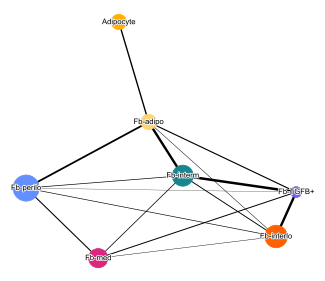

In [20]:
paga_fig(adata, LABEL, f'Fig1a_paga_graph_{LABEL}', width='single', height_mm=75)

### 4.2 The same graph on the UMAP

Nodes placed at each population's **median UMAP coordinate**, so the abstracted graph can be read
against the embedding it came from. The two panels answer different questions and both are worth
having: the layout above is driven by the connectivities alone, this one by the UMAP, and an edge
that survives in both is not an artefact of either layout.

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig1b_paga_onUMAP_taa_l3_cmx_2026-09-03.{pdf}   88 x 75 mm


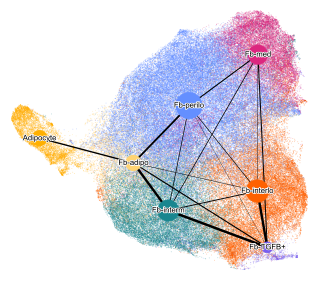

In [21]:
paga_on_embedding(adata, LABEL, 'X_umap', P.POP_COLORS, f'Fig1b_paga_onUMAP_{LABEL}')

**What the graph says** (values from the run of 2026-09-02; re-read them from the table above
if anything upstream changes). `Adipocyte` is a clean terminal branch: its only connection above
0.04 is to **`Fb-adipo` (0.51)**, and it is essentially unconnected to everything else
(`Fb-perilo` 0.03, `Fb-interm` 0.03, `Fb-interlo` 0.007). So the mature adipocytes attach to the
rest of the compartment through `Fb-adipo` and nowhere else -- the same conclusion the original
notebook drew, now on three assays and a 146k-cell graph.

Behind it the strongest links are `Fb-interm`-`Fb-TGFB+` (0.93), `Fb-interlo`-`Fb-TGFB+` (0.89),
`Fb-interm`-`Fb-adipo` (0.89) and `Fb-perilo`-`Fb-adipo` (0.66), which reads as an
interlobular/perilobular -> activated (`Fb-interm`, `Fb-TGFB+`) -> `Fb-adipo` -> `Adipocyte` axis.

Two cautions before this is read as a lineage. PAGA measures **connectivity in a kNN graph, not
flow**: it is undirected, and the arrangement above is an interpretation of which populations sit
next to which, not evidence of a differentiation direction or a rate. And `Fb-TGFB+` is 1,713
cells; a small group has fewer neighbours to place, which makes its connectivities noisier than
the node areas suggest.

### 4.3 `taa_l3_cmx` x modality -- a control, and why it is a heatmap

The same computation with the populations split by assay, to check that the trajectory is not a
batch effect. It passes, and in doing so it defeats its own node-link rendering.

Splitting seven populations three ways makes the groups small and, within a population, nearly
identical -- so PAGA's observed-over-expected ratio **saturates**: 43 of the 210 pairs sit at
exactly 1.0, and 63 are above 0.6. No threshold separates signal from ceiling, and a 21-node graph
with ~50 edges is a hairball whatever the layout. So this view is drawn as a heatmap of the full
matrix instead, which shows the block structure the graph cannot.

Read the diagonal blocks first: the three assays of one population connect to each other at 1.0,
which is the integration working -- a cell's nearest neighbours are the same population regardless
of which assay measured it. If the graph were driven by batch, the bright blocks would instead run
along *assay*, linking `*-xenium` to `*-xenium` across different populations.

In [22]:
sc.tl.paga(adata_mod, groups=LABEL_MOD)

M_mod = paga_table(adata_mod, ORDER_MOD, f'paga_connectivities_{LABEL_MOD}')
pd.Series(adata_mod.uns[f'{LABEL_MOD}_sizes'], index=ORDER_MOD, name='n_cells').to_csv(
    f'{RES}/paga_group_sizes_{LABEL_MOD}_{today}.csv')

off = M_mod.to_numpy()[np.triu_indices(len(ORDER_MOD), k=1)]
print(f'\n{len(off)} pairs | {(off >= 0.99).sum()} at the 1.0 ceiling | '
      f'{(off >= 0.6).sum()} above 0.6 | median {np.median(off):.3f}')
M_mod.round(3)

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/results/Fb_adipo_paga_revision/paga_connectivities_taa_l3_cmx_modality_2026-09-03.csv

210 pairs | 43 at the 1.0 ceiling | 63 above 0.6 | median 0.268


,Fb-interlo-scell,Fb-interlo-multiome,Fb-interlo-xenium,Fb-perilo-scell,Fb-perilo-multiome,Fb-perilo-xenium,Fb-med-scell,Fb-med-multiome,Fb-med-xenium,Fb-interm-scell,Fb-interm-multiome,Fb-interm-xenium,Fb-TGFB+-scell,Fb-TGFB+-multiome,Fb-TGFB+-xenium,Fb-adipo-scell,Fb-adipo-multiome,Fb-adipo-xenium,Adipocyte-scell,Adipocyte-multiome,Adipocyte-xenium
Fb-interlo-scell,0.000,1.000,1.000,0.295,0.170,0.174,0.197,0.140,0.107,0.452,0.406,0.273,1.000,0.614,0.469,0.267,0.096,0.144,0.050,0.008,0.006
Fb-interlo-multiome,1.000,0.000,1.000,0.176,0.390,0.112,0.050,0.336,0.042,0.311,0.821,0.196,1.000,1.000,0.617,0.088,0.044,0.043,0.014,0.029,0.002
Fb-interlo-xenium,1.000,1.000,0.000,0.217,0.183,0.390,0.131,0.240,0.269,0.207,0.192,0.367,0.569,0.326,1.000,0.149,0.038,0.167,0.022,0.014,0.006
Fb-perilo-scell,0.295,0.176,0.217,0.000,1.000,1.000,0.671,0.925,0.201,0.320,0.368,0.251,0.085,0.032,0.131,1.000,0.807,0.507,0.195,0.176,0.021
Fb-perilo-multiome,0.170,0.390,0.183,1.000,0.000,1.000,0.318,1.000,0.107,0.303,0.711,0.244,0.048,0.039,0.034,0.617,1.000,0.216,0.139,0.520,0.019
Fb-perilo-xenium,0.174,0.112,0.390,1.000,1.000,0.000,0.359,0.611,0.373,0.160,0.152,0.289,0.103,0.008,0.395,0.537,0.268,0.534,0.093,0.117,0.023
Fb-med-scell,0.197,0.050,0.131,0.671,0.318,0.359,0.000,1.000,1.000,0.356,0.113,0.297,0.221,0.101,0.477,0.079,0.053,0.020,0.018,0.000,0.001
Fb-med-multiome,0.140,0.336,0.240,0.925,1.000,0.611,1.000,0.000,1.000,0.399,0.929,0.482,0.807,1.000,1.000,0.162,0.379,0.055,0.041,0.260,0.006
Fb-med-xenium,0.107,0.042,0.269,0.201,0.107,0.373,1.000,1.000,0.000,0.147,0.036,0.435,0.260,0.104,1.000,0.028,0.001,0.008,0.006,0.010,0.001
Fb-interm-scell,0.452,0.311,0.207,0.320,0.303,0.160,0.356,0.399,0.147,0.000,1.000,1.000,1.000,0.782,0.293,1.000,0.541,0.467,0.150,0.036,0.010


-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig2_paga_heatmap_taa_l3_cmx_modality_2026-09-03.{pdf}   130 x 110 mm


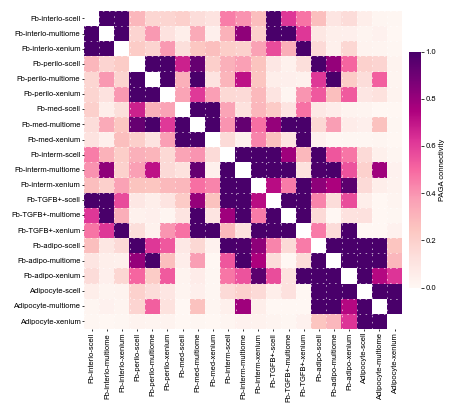

In [23]:
fig, ax = plt.subplots(figsize=P.figsize_mm('one-half', 110))

Mp = M_mod.to_numpy().copy()
np.fill_diagonal(Mp, np.nan)                      # self-connectivity is 0 by construction
im = ax.imshow(Mp, cmap=P.CMAP_USAGE, vmin=0, vmax=1,
               interpolation='nearest')           # 'antialiased' would smear a 21x21 grid

ax.set_xticks(range(len(ORDER_MOD)), ORDER_MOD, rotation=90, fontsize=5)
ax.set_yticks(range(len(ORDER_MOD)), ORDER_MOD, fontsize=5)
ax.set_xticks(np.arange(-0.5, len(ORDER_MOD), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(ORDER_MOD), 1), minor=True)
ax.grid(which='minor', color='w', linewidth=0.4)
ax.tick_params(which='minor', length=0)
ax.tick_params(which='major', length=1.5)
for s in ax.spines.values():
    s.set_visible(False)

cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label('PAGA connectivity', fontsize=5)
cb.ax.tick_params(labelsize=5)
cb.outline.set_visible(False)

fig.subplots_adjust(left=0.26, bottom=0.24, right=0.86, top=0.99)
P.save(fig, f'{FIGS}/Fig2_paga_heatmap_{LABEL_MOD}_{today}.pdf')
plt.show()

In [24]:
# the same-population cross-assay edges, listed -- the control, as a number rather than a colour
same = [(p, m1, m2, M_mod.loc[f'{p}-{m1}', f'{p}-{m2}'])
        for p in ORDER_CMX
        for i, m1 in enumerate(P.MODALITY_ORDER) for m2 in P.MODALITY_ORDER[i + 1:]
        if f'{p}-{m1}' in ORDER_MOD and f'{p}-{m2}' in ORDER_MOD]
same = pd.DataFrame(same, columns=['population', 'assay_a', 'assay_b', 'connectivity'])
same.to_csv(f'{RES}/paga_crossAssay_samePopulation_{today}.csv', index=False)
print(f'{(same["connectivity"] >= 0.99).sum()} of {len(same)} same-population cross-assay pairs '
      f'are at the 1.0 ceiling; min {same["connectivity"].min():.3f}')
same

21 of 21 same-population cross-assay pairs are at the 1.0 ceiling; min 1.000


,population,assay_a,assay_b,connectivity
0,Fb-interlo,scell,multiome,1.0
1,Fb-interlo,scell,xenium,1.0
2,Fb-interlo,multiome,xenium,1.0
3,Fb-perilo,scell,multiome,1.0
4,Fb-perilo,scell,xenium,1.0
5,Fb-perilo,multiome,xenium,1.0
6,Fb-med,scell,multiome,1.0
7,Fb-med,scell,xenium,1.0
8,Fb-med,multiome,xenium,1.0
9,Fb-interm,scell,multiome,1.0


## 5. ForceAtlas2 embedding, initialised from PAGA

The step the original notebook ran next. `init_pos='paga'` seeds the force layout with the node
positions `sc.pl.paga` computed in §4.1, which is the point of the PAGA/ForceAtlas2 pairing: the
coarse topology is fixed first and the single cells are then laid out inside it, so the embedding
keeps the global structure a UMAP tends to tear.

Read it alongside the UMAP rather than instead of it. Both are 2-D projections of the same kNN
graph and neither distance is metric; a branch that appears in both is worth more than one that
appears in either.

**This is the slow cell**: the force layout over 146,178 cells and 2.7M edges took **36 min** on
4 cores. It is therefore cached to a parquet next to the results -- re-running the notebook reuses
the saved coordinates and takes about two minutes end to end. Delete
`results/Fb_adipo_paga_revision/X_draw_graph_fa_taa_l3_cmx.parquet` to recompute it.

In [25]:
%%time
# Cached, because this is a ~36 minute force layout over 146k cells and 2.7M edges. Delete the
# parquet to recompute. The cache is keyed to the cell order, and the assert below fails loudly
# rather than silently pairing coordinates with the wrong cells if the object ever changes.
FA_CACHE = f'{RES}/X_draw_graph_fa_{LABEL}.parquet'

if os.path.exists(FA_CACHE):
    fa = pd.read_parquet(FA_CACHE)
    assert fa.index.equals(pd.Index(adata.obs_names)), 'cache does not match this object'
    adata.obsm['X_draw_graph_fa'] = fa.to_numpy()
    print(f'loaded cached layout <- {FA_CACHE}')
else:
    sc.tl.draw_graph(adata, layout='fa', init_pos='paga', random_state=0)
    pd.DataFrame(adata.obsm['X_draw_graph_fa'], columns=['fa1', 'fa2'],
                 index=adata.obs_names).to_parquet(FA_CACHE)
    print(f'computed and cached -> {FA_CACHE}')

adata.obsm['X_draw_graph_fa'].shape

loaded cached layout <- /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/results/Fb_adipo_paga_revision/X_draw_graph_fa_taa_l3_cmx.parquet


CPU times: user 40.2 ms, sys: 45.9 ms, total: 86.1 ms
Wall time: 198 ms


(146178, 2)

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig5a_forceAtlas2_taa_l3_cmx_modality_2026-09-03.{pdf}   130 x 80 mm


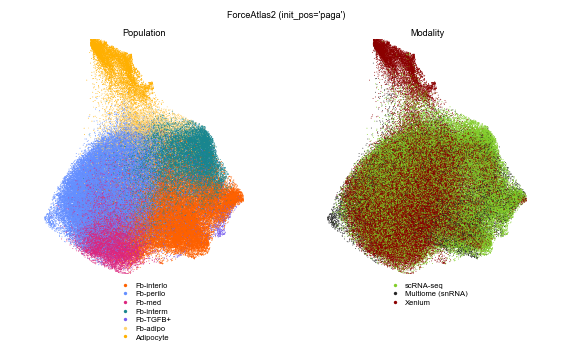

In [26]:
fig = P.umap_grid(
    adata.obs, adata.obsm['X_draw_graph_fa'], [LABEL, 'modality'],
    titles=['Population', 'Modality'],
    palettes={LABEL: P.POP_COLORS, 'modality': P.MODALITY_COLORS},
    orders={LABEL: ORDER_CMX,
            'modality': P.order_present(adata.obs['modality'], P.MODALITY_ORDER)},
    names={'modality': P.MODALITY_NAMES},
    ncols=2, point_size=0.35, width='one-half', panel_height_mm=58, legend_height_mm=16,
    suptitle='ForceAtlas2 (init_pos=\'paga\')')
P.save(fig, f'{FIGS}/Fig5a_forceAtlas2_{LABEL}_modality_{today}.pdf')
plt.show()

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig5b_umap_taa_l3_cmx_modality_2026-09-03.{pdf}   130 x 80 mm


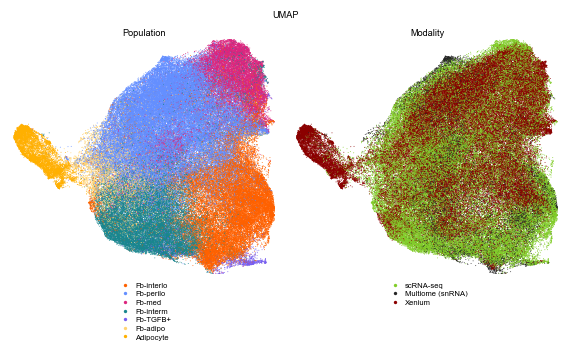

In [27]:
# the same embedding side by side with the UMAP, so the two projections can be compared directly
fig = P.umap_grid(
    adata.obs, adata.obsm['X_umap'], [LABEL, 'modality'],
    titles=['Population', 'Modality'],
    palettes={LABEL: P.POP_COLORS, 'modality': P.MODALITY_COLORS},
    orders={LABEL: ORDER_CMX,
            'modality': P.order_present(adata.obs['modality'], P.MODALITY_ORDER)},
    names={'modality': P.MODALITY_NAMES},
    ncols=2, point_size=0.35, width='one-half', panel_height_mm=58, legend_height_mm=16,
    suptitle='UMAP')
P.save(fig, f'{FIGS}/Fig5b_umap_{LABEL}_modality_{today}.pdf')
plt.show()

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig5c_paga_onForceAtlas2_taa_l3_cmx_2026-09-03.{pdf}   88 x 75 mm


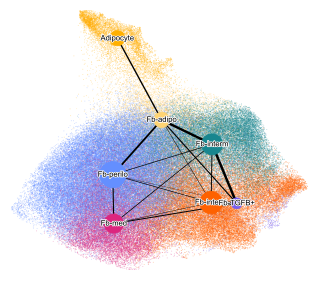

In [28]:
# and the PAGA graph over the ForceAtlas2 embedding, the counterpart of Fig1b
paga_on_embedding(adata, LABEL, 'X_draw_graph_fa', P.POP_COLORS,
                  f'Fig5c_paga_onForceAtlas2_{LABEL}')

## 6. Marker dotplots

Every panel is drawn twice and both are kept, because the two colour bars mean different things
and must never be mixed in one composite:

* **gene-scaled** (`standard_scale='var'`, the unsuffixed file) -- each gene min-max scaled across
  the rows, so the colour is "high or low *for this gene*" and a specific but lowly expressed
  marker such as `LEP` or `ADIPOQ` is still legible;
* **raw** (`_unscaled`) -- the log-normalised mean, comparable *between* genes, and therefore
  dominated by whatever is abundant.

`mean_only_expressed=True` throughout: the colour is the mean over expressing cells only, so it
reads as "how much, where detected" and does not re-encode the detection rate the dot area
already shows.

In [29]:
MEAN_ONLY_EXPRESSED = True

def dotplot_pair(ad_, panel, groupby, order, stem, width_mm, height_mm=None):
    height_mm = max(30.0, 3.6 * len(order) + 12.0) if height_mm is None else height_mm
    for scale, sfx in [('var', ''), (None, '_unscaled')]:
        P.dotplot(ad_, panel, groupby=groupby, categories_order=order,
                  width_mm=width_mm, height_mm=height_mm, standard_scale=scale,
                  mean_only_expressed=MEAN_ONLY_EXPRESSED,
                  path=f'{FIGS}/{stem}{sfx}_{today}.pdf')

### 6.1 `taa_l3_cmx`

The staged adipose panel first -- it is the one that carries the trajectory, running left to right
from the progenitor markers to the mature adipocyte hormones -- then the identity/activity panel
that says what every other population is.

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig3a_dotplot_adiposeDifferentiation_taa_l3_cmx_2026-09-03.pdf   140 x 37 mm (cropped to content)


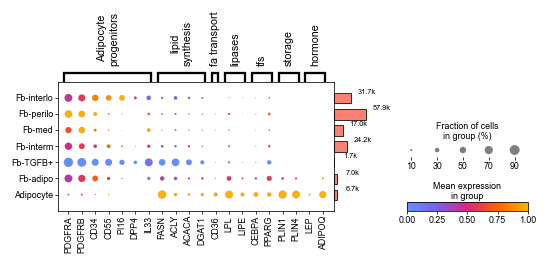

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig3a_dotplot_adiposeDifferentiation_taa_l3_cmx_unscaled_2026-09-03.pdf   140 x 37 mm (cropped to content)


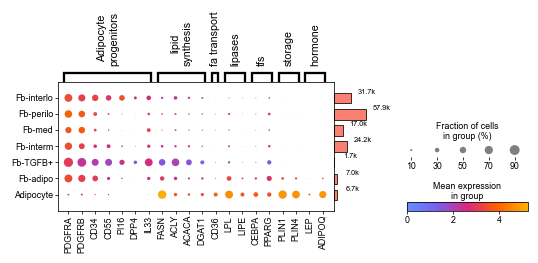

In [30]:
dotplot_pair(adata, ADIPOSE_X, LABEL, ORDER_CMX,
             f'Fig3a_dotplot_adiposeDifferentiation_{LABEL}', width_mm=140)

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig3b_dotplot_identityActivity_taa_l3_cmx_2026-09-03.pdf   183 x 37 mm (cropped to content)


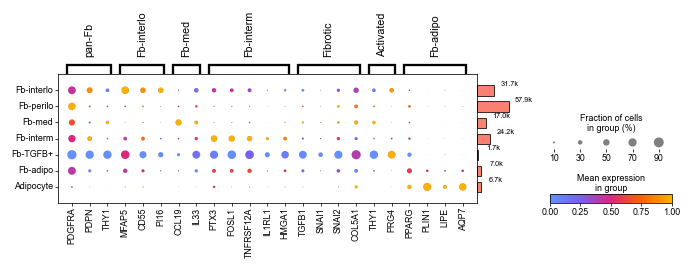

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig3b_dotplot_identityActivity_taa_l3_cmx_unscaled_2026-09-03.pdf   183 x 37 mm (cropped to content)


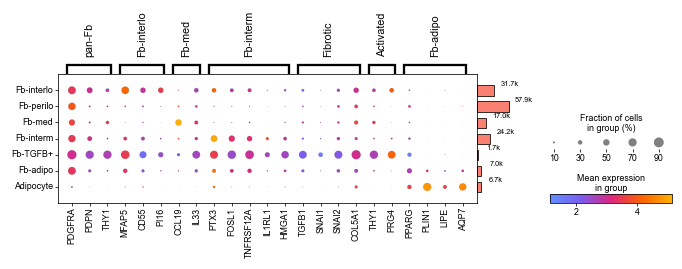

In [31]:
dotplot_pair(adata, ALL_X, LABEL, ORDER_CMX,
             f'Fig3b_dotplot_identityActivity_{LABEL}', width_mm=183)

### 6.2 `taa_l3_cmx` x modality

The same two panels with one row per population and assay. `Adipocyte` is overwhelmingly an
in-situ population -- 6,195 of its 6,726 cells are Xenium -- because mature adipocytes are largely
lost in dissociation. The 430 scRNA-seq and 101 multiome adipocytes are enough to draw a row, and
worth looking at precisely because they are the ones that survived, but not enough to weigh
against the Xenium row.

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig4a_dotplot_adiposeDifferentiation_taa_l3_cmx_modality_2026-09-03.pdf   140 x 88 mm (cropped to content)


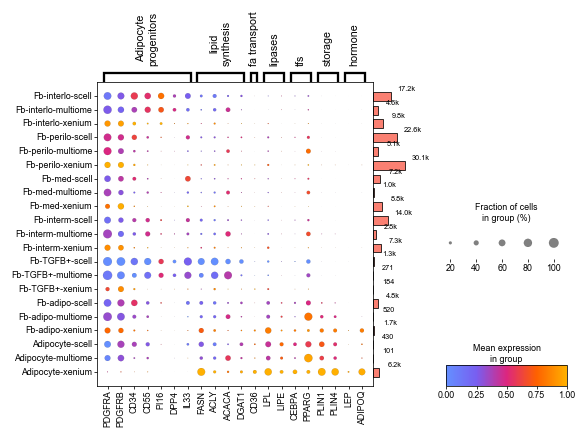

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig4a_dotplot_adiposeDifferentiation_taa_l3_cmx_modality_unscaled_2026-09-03.pdf   140 x 88 mm (cropped to content)


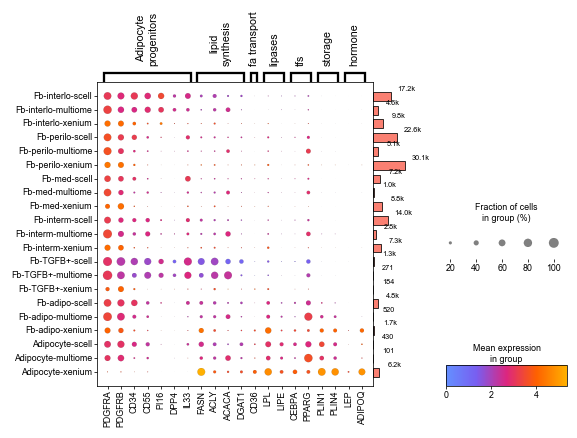

In [32]:
dotplot_pair(adata_mod, ADIPOSE_X, LABEL_MOD, ORDER_MOD,
             f'Fig4a_dotplot_adiposeDifferentiation_{LABEL_MOD}', width_mm=140)

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig4b_dotplot_identityActivity_taa_l3_cmx_modality_2026-09-03.pdf   183 x 88 mm (cropped to content)


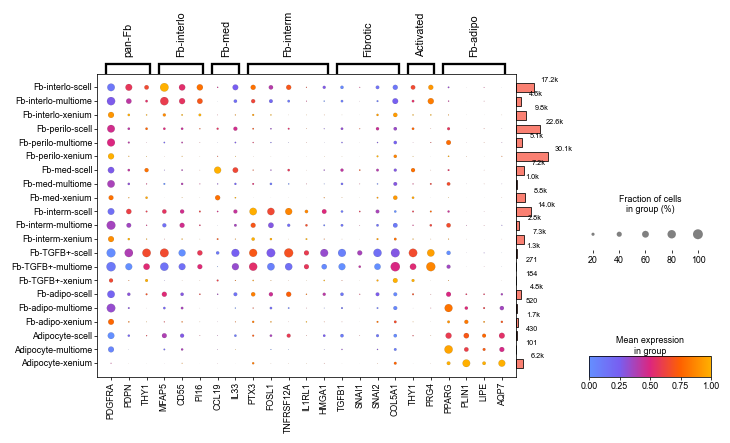

-> /nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/plots/Fb_adipo_paga_revision/Fig4b_dotplot_identityActivity_taa_l3_cmx_modality_unscaled_2026-09-03.pdf   183 x 88 mm (cropped to content)


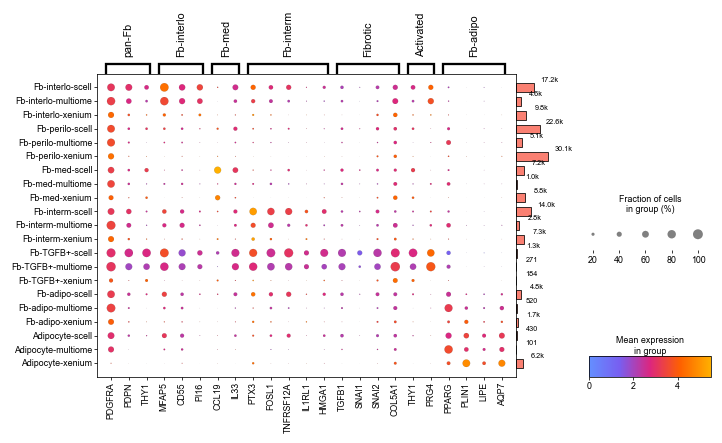

In [33]:
dotplot_pair(adata_mod, ALL_X, LABEL_MOD, ORDER_MOD,
             f'Fig4b_dotplot_identityActivity_{LABEL_MOD}', width_mm=183)

## 7. Outputs

In [34]:
import glob
files = sorted(glob.glob(f'{FIGS}/*{today}*') + glob.glob(f'{RES}/*{today}*'))
pd.DataFrame({'file': [f.replace(repo_path + '/', '') for f in files],
              'KB': [round(os.path.getsize(f) / 1024) for f in files]})

,file,KB
0,plots/Fb_adipo_paga_revision/Fig1a_paga_graph_...,20
1,plots/Fb_adipo_paga_revision/Fig1b_paga_onUMAP...,2714
2,plots/Fb_adipo_paga_revision/Fig2_paga_heatmap...,52
3,plots/Fb_adipo_paga_revision/Fig3a_dotplot_adi...,54
4,plots/Fb_adipo_paga_revision/Fig3a_dotplot_adi...,54
5,plots/Fb_adipo_paga_revision/Fig3b_dotplot_ide...,59
6,plots/Fb_adipo_paga_revision/Fig3b_dotplot_ide...,59
7,plots/Fb_adipo_paga_revision/Fig4a_dotplot_adi...,102
8,plots/Fb_adipo_paga_revision/Fig4a_dotplot_adi...,102
9,plots/Fb_adipo_paga_revision/Fig4b_dotplot_ide...,115
